# Brain MRI Tumor Segmentation with DeepLabV3+

Patient-level brain tumor segmentation on the LGG MRI Segmentation dataset using DeepLabV3+ with an ImageNet-pretrained MobileNetV2 encoder.

## Project overview

This notebook downloads the dataset directly from Kaggle, creates leakage-safe patient-level train/validation/test splits, trains a DeepLabV3+ model, selects the segmentation threshold only on the validation set, and reports final test metrics.

Main evaluation metrics:

- Global Dice and IoU
- Mean per-image Dice and IoU
- Tumor-positive image Dice and IoU
- Precision, recall, specificity, and pixel accuracy
- False-positive rate on tumor-free slices

> Recommended runtime: Google Colab with a GPU accelerator.

In [1]:
!pip install -q kagglehub

In [2]:
import json
import random
from pathlib import Path

import cv2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import Model, layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Download and inspect the dataset

The dataset is downloaded through kagglehub; no manual upload is required. A single canonical kaggle_3m directory is selected to prevent duplicate counting when the archive contains nested copies.

In [3]:
dataset_path = Path(kagglehub.dataset_download("mateuszbuda/lgg-mri-segmentation"))

direct_root = dataset_path / "kaggle_3m"
if direct_root.is_dir():
    data_root = direct_root
else:
    candidates = sorted(
        [path for path in dataset_path.rglob("kaggle_3m") if path.is_dir()],
        key=lambda path: (len(path.parts), str(path))
    )
    if not candidates:
        raise FileNotFoundError("The kaggle_3m directory was not found.")
    data_root = candidates[0]

patient_dirs = sorted(path for path in data_root.iterdir() if path.is_dir())

print("Dataset cache:", dataset_path)
print("Selected data root:", data_root)
print("Patients:", len(patient_dirs))

Using Colab cache for faster access to the 'lgg-mri-segmentation' dataset.
Dataset cache: /kaggle/input/lgg-mri-segmentation
Selected data root: /kaggle/input/lgg-mri-segmentation/kaggle_3m
Patients: 110


In [4]:
def get_image_mask_pairs(directories):
    image_paths = []
    mask_paths = []

    for patient_dir in directories:
        for image_path in sorted(patient_dir.glob("*.tif")):
            if image_path.name.endswith("_mask.tif"):
                continue

            mask_path = image_path.with_name(f"{image_path.stem}_mask.tif")
            if mask_path.exists():
                image_paths.append(str(image_path))
                mask_paths.append(str(mask_path))

    return image_paths, mask_paths

def mask_is_positive(mask_path):
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(f"Could not read mask: {mask_path}")
    return bool(np.any(mask > 0))

all_images, all_masks = get_image_mask_pairs(patient_dirs)
all_positive_count = sum(mask_is_positive(path) for path in all_masks)

print("Unique image-mask pairs:", len(all_images))
print("Tumor-positive slices:", all_positive_count)
print("Tumor-free slices:", len(all_masks) - all_positive_count)

Unique image-mask pairs: 3929
Tumor-positive slices: 1373
Tumor-free slices: 2556


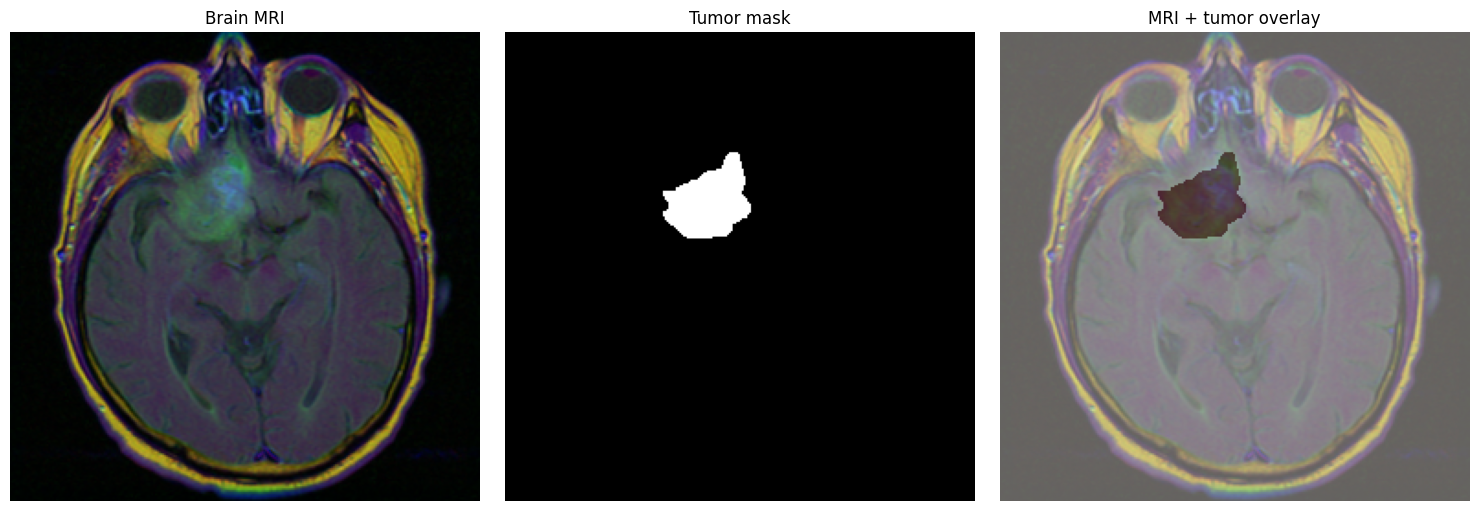

In [5]:
positive_index = next(index for index, path in enumerate(all_masks) if mask_is_positive(path))
sample_image = cv2.cvtColor(cv2.imread(all_images[positive_index]), cv2.COLOR_BGR2RGB)
sample_mask = cv2.imread(all_masks[positive_index], cv2.IMREAD_GRAYSCALE)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sample_image)
axes[0].set_title("Brain MRI")
axes[1].imshow(sample_mask, cmap="gray")
axes[1].set_title("Tumor mask")
axes[2].imshow(sample_image)
axes[2].imshow(sample_mask, cmap="Reds", alpha=0.4)
axes[2].set_title("MRI + tumor overlay")

for axis in axes:
    axis.axis("off")

plt.tight_layout()
plt.show()

## 2. Leakage-safe patient-level split

All slices from the same patient remain in one subset. The split is stratified by whether a patient has at least one tumor-positive mask.

In [6]:
def patient_has_tumor(patient_dir):
    return int(any(mask_is_positive(path) for path in patient_dir.glob("*_mask.tif")))

patient_labels = [patient_has_tumor(path) for path in patient_dirs]

train_dirs, temporary_dirs, _, temporary_labels = train_test_split(
    patient_dirs,
    patient_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=patient_labels
)

val_dirs, test_dirs = train_test_split(
    temporary_dirs,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_labels
)

train_images, train_masks = get_image_mask_pairs(train_dirs)
val_images, val_masks = get_image_mask_pairs(val_dirs)
test_images, test_masks = get_image_mask_pairs(test_dirs)

def split_summary(name, directories, image_paths, mask_paths):
    positive_count = sum(mask_is_positive(path) for path in mask_paths)
    return {
        "split": name,
        "patients": len(directories),
        "slices": len(image_paths),
        "positive_slices": positive_count,
        "empty_slices": len(mask_paths) - positive_count
    }

split_df = pd.DataFrame([
    split_summary("Train", train_dirs, train_images, train_masks),
    split_summary("Validation", val_dirs, val_images, val_masks),
    split_summary("Test", test_dirs, test_images, test_masks)
])
split_df

,split,patients,slices,positive_slices,empty_slices
0,Train,88,3165,1137,2028
1,Validation,11,386,109,277
2,Test,11,378,127,251


In [7]:
# Verify the existing patient-level splits without changing them.
train_patient_ids = {patient_dir.name for patient_dir in train_dirs}
val_patient_ids = {patient_dir.name for patient_dir in val_dirs}
test_patient_ids = {patient_dir.name for patient_dir in test_dirs}

assert train_patient_ids.isdisjoint(val_patient_ids), (
    f"Patient overlap between train and validation: {sorted(train_patient_ids & val_patient_ids)}"
)
assert train_patient_ids.isdisjoint(test_patient_ids), (
    f"Patient overlap between train and test: {sorted(train_patient_ids & test_patient_ids)}"
)
assert val_patient_ids.isdisjoint(test_patient_ids), (
    f"Patient overlap between validation and test: {sorted(val_patient_ids & test_patient_ids)}"
)

print("Patient split check passed: train, validation, and test patient IDs are disjoint.")


Patient split check passed: train, validation, and test patient IDs are disjoint.


## 3. Input pipeline

MRI images are resized to 256 × 256 and mapped to the [-1, 1] input range expected by MobileNetV2. Masks use nearest-neighbor resizing and remain binary.

In [8]:
IMG_SIZE = 256
BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

def read_pair(image_path, mask_path):
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if image is None or mask is None:
        raise FileNotFoundError(f"Could not read pair: {image_path}, {mask_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    image = image.astype(np.float32) / 127.5 - 1.0

    mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    mask = (mask > 0).astype(np.float32)[..., None]

    return image, mask

def load_pair_numpy(image_path, mask_path):
    return read_pair(image_path.decode("utf-8"), mask_path.decode("utf-8"))

def load_pair_tensor(image_path, mask_path):
    image, mask = tf.numpy_function(
        load_pair_numpy,
        [image_path, mask_path],
        [tf.float32, tf.float32]
    )
    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return image, mask

def augment_pair(image, mask):
    flip = tf.random.uniform(()) > 0.5
    image = tf.cond(flip, lambda: tf.image.flip_left_right(image), lambda: image)
    mask = tf.cond(flip, lambda: tf.image.flip_left_right(mask), lambda: mask)
    image = tf.image.random_brightness(image, max_delta=0.08)
    image = tf.image.random_contrast(image, lower=0.90, upper=1.10)
    image = tf.clip_by_value(image, -1.0, 1.0)
    return image, mask

def build_dataset(image_paths, mask_paths, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(image_paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(load_pair_tensor, num_parallel_calls=AUTOTUNE)

    if training:
        dataset = dataset.map(augment_pair, num_parallel_calls=AUTOTUNE)

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = build_dataset(train_images, train_masks, training=True)
val_ds = build_dataset(val_images, val_masks)
test_ds = build_dataset(test_images, test_masks)

In [9]:
sample_batch_images, sample_batch_masks = next(iter(train_ds))

print("Image batch shape:", sample_batch_images.shape)
print("Mask batch shape:", sample_batch_masks.shape)
print("Image range:", float(tf.reduce_min(sample_batch_images)), float(tf.reduce_max(sample_batch_images)))
print("Mask values:", np.unique(sample_batch_masks.numpy()))

Image batch shape: (8, 256, 256, 3)
Mask batch shape: (8, 256, 256, 1)
Image range: -1.0 0.8605769276618958
Mask values: [0. 1.]


## 4. Loss and training metrics

The original BCE + per-image soft Dice loss is preserved. Epoch Soft Dice/IoU metrics aggregate one score per image, including the final short batch. Deterministic code checks below verify the formulas and batch invariance without training.


In [10]:
def soft_dice_coefficient(y_true, y_pred, smooth=1e-6):
    axes = (1, 2, 3)
    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    denominator = tf.reduce_sum(y_true, axis=axes) + tf.reduce_sum(y_pred, axis=axes)
    score = (2.0 * intersection + smooth) / (denominator + smooth)
    return tf.reduce_mean(score)

def soft_iou_coefficient(y_true, y_pred, smooth=1e-6):
    axes = (1, 2, 3)
    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    union = (
        tf.reduce_sum(y_true, axis=axes)
        + tf.reduce_sum(y_pred, axis=axes)
        - intersection
    )
    score = (intersection + smooth) / (union + smooth)
    return tf.reduce_mean(score)

def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + (1.0 - soft_dice_coefficient(y_true, y_pred))

In [11]:
# Return one score per image so the final short batch has the correct weight.
# The original scalar functions and BCE + Dice loss remain unchanged.
def soft_dice_per_image(y_true, y_pred, smooth=1e-6):
    axes = (1, 2, 3)
    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    denominator = tf.reduce_sum(y_true, axis=axes) + tf.reduce_sum(y_pred, axis=axes)
    return (2.0 * intersection + smooth) / (denominator + smooth)


def soft_iou_per_image(y_true, y_pred, smooth=1e-6):
    axes = (1, 2, 3)
    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    union = (
        tf.reduce_sum(y_true, axis=axes)
        + tf.reduce_sum(y_pred, axis=axes)
        - intersection
    )
    return (intersection + smooth) / (union + smooth)


def verify_training_metric_formulas():
    """Deterministic tensor checks only; no fitting, model changes, or RNG calls."""
    true = tf.constant([
        [[[1.0], [0.0]], [[0.0], [0.0]]],
        [[[0.0], [0.0]], [[0.0], [0.0]]],
        [[[1.0], [0.0]], [[0.0], [0.0]]],
    ], dtype=tf.float32)
    probability = tf.constant([
        [[[1.0], [0.0]], [[0.0], [0.0]]],
        [[[0.0], [0.0]], [[0.0], [0.0]]],
        [[[0.0], [1.0]], [[0.0], [0.0]]],
    ], dtype=tf.float32)
    expected_dice = np.array([1.0, 1.0, 1e-6 / (2.0 + 1e-6)])
    expected_iou = np.array([1.0, 1.0, 1e-6 / (2.0 + 1e-6)])
    np.testing.assert_allclose(soft_dice_per_image(true, probability).numpy(), expected_dice, rtol=1e-6)
    np.testing.assert_allclose(soft_iou_per_image(true, probability).numpy(), expected_iou, rtol=1e-6)
    np.testing.assert_allclose(float(soft_dice_coefficient(true, probability)), expected_dice.mean(), rtol=1e-6)
    np.testing.assert_allclose(float(soft_iou_coefficient(true, probability)), expected_iou.mean(), rtol=1e-6)

    # The corrected epoch metric must be invariant to batch partitioning.
    for batch_size in (1, 2, 3):
        dice_metric = tf.keras.metrics.MeanMetricWrapper(soft_dice_per_image)
        iou_metric = tf.keras.metrics.MeanMetricWrapper(soft_iou_per_image)
        for start in range(0, 3, batch_size):
            dice_metric.update_state(true[start:start + batch_size], probability[start:start + batch_size])
            iou_metric.update_state(true[start:start + batch_size], probability[start:start + batch_size])
        np.testing.assert_allclose(float(dice_metric.result()), expected_dice.mean(), rtol=1e-6)
        np.testing.assert_allclose(float(iou_metric.result()), expected_iou.mean(), rtol=1e-6)

    # Check the unchanged loss formula on non-saturated probabilities.
    soft_probability = 0.1 + 0.8 * probability
    expected_loss = (
        tf.reduce_mean(tf.keras.losses.binary_crossentropy(true, soft_probability))
        + 1.0 - tf.reduce_mean(soft_dice_per_image(true, soft_probability))
    )
    np.testing.assert_allclose(
        float(bce_dice_loss(true, soft_probability)), float(expected_loss), rtol=1e-6
    )
    print("Training Soft Dice/IoU, unequal-batch aggregation, and unchanged loss checks passed.")


verify_training_metric_formulas()


Training Soft Dice/IoU, unequal-batch aggregation, and unchanged loss checks passed.


## 5. DeepLabV3+ with MobileNetV2 encoder

The decoder combines ASPP context features with low-level spatial features from MobileNetV2. The encoder is frozen during warm-up and partially unfrozen for fine-tuning.

In [12]:
def convolution_block(x, filters=256, kernel_size=3, dilation_rate=1):
    x = layers.Conv2D(
        filters,
        kernel_size,
        padding="same",
        dilation_rate=dilation_rate,
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation("relu")(x)

def aspp_block(x):
    height, width = int(x.shape[1]), int(x.shape[2])

    pooled = layers.GlobalAveragePooling2D(keepdims=True)(x)
    pooled = convolution_block(pooled, filters=256, kernel_size=1)
    pooled = layers.Resizing(height, width, interpolation="bilinear")(pooled)

    branch_1 = convolution_block(x, filters=256, kernel_size=1, dilation_rate=1)
    branch_2 = convolution_block(x, filters=256, kernel_size=3, dilation_rate=6)
    branch_3 = convolution_block(x, filters=256, kernel_size=3, dilation_rate=12)
    branch_4 = convolution_block(x, filters=256, kernel_size=3, dilation_rate=18)

    x = layers.Concatenate()([pooled, branch_1, branch_2, branch_3, branch_4])
    return convolution_block(x, filters=256, kernel_size=1)

def build_deeplabv3plus(input_shape=(256, 256, 3)):
    inputs = layers.Input(shape=input_shape)

    backbone = tf.keras.applications.MobileNetV2(
        input_tensor=inputs,
        weights="imagenet",
        include_top=False
    )
    backbone.trainable = False

    low_level = backbone.get_layer("block_3_expand_relu").output
    encoder_output = backbone.get_layer("block_13_expand_relu").output

    x = aspp_block(encoder_output)
    x = layers.Resizing(
        int(low_level.shape[1]),
        int(low_level.shape[2]),
        interpolation="bilinear"
    )(x)

    low_level = convolution_block(low_level, filters=48, kernel_size=1)
    x = layers.Concatenate()([x, low_level])
    x = convolution_block(x, filters=256, kernel_size=3)
    x = convolution_block(x, filters=256, kernel_size=3)
    x = layers.Resizing(input_shape[0], input_shape[1], interpolation="bilinear")(x)
    outputs = layers.Conv2D(1, kernel_size=1, activation="sigmoid")(x)

    model = Model(inputs, outputs, name="DeepLabV3Plus_MobileNetV2")
    return model, backbone

model, backbone = build_deeplabv3plus((IMG_SIZE, IMG_SIZE, 3))
model.summary()

/tmp/ipykernel_3018/4252775762.py:30: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "DeepLabV3Plus_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 128, 128,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 128, 128,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 128, 128,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 128, 128,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 128, 128,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 128, 128,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 128, 128,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 128, 128,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 129, 129,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 64, 64,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 64, 64,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 64, 64,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 64, 64,    │      2,304 │ block_1_depthwis

 Total params: 6,525,953 (24.89 MB)

 Trainable params: 5,905,505 (22.53 MB)

 Non-trainable params: 620,448 (2.37 MB)

## 6. Training

Training uses two stages: decoder warm-up with the encoder frozen, followed by low-learning-rate fine-tuning of the final MobileNetV2 layers.

In [13]:
BEST_MODEL_PATH = "best_deeplabv3plus_brain_mri.keras"
WARMUP_WEIGHTS_PATH = "warmup_best.weights.h5"
FINE_TUNE_WEIGHTS_PATH = "finetune_best.weights.h5"
WARMUP_EPOCHS = 5
FINE_TUNE_EPOCHS = 20

def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=bce_dice_loss,
        metrics=[
            tf.keras.metrics.MeanMetricWrapper(
                soft_dice_per_image, name="soft_dice_coefficient"
            ),
            tf.keras.metrics.MeanMetricWrapper(
                soft_iou_per_image, name="soft_iou_coefficient"
            )
        ]
    )

def make_callbacks(checkpoint_path):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            save_weights_only=True,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.5,
            patience=3,
            min_lr=1e-7,
            verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=7,
            restore_best_weights=True,
            verbose=1
        )
    ]

In [14]:
compile_model(model, learning_rate=1e-3)

history_warmup = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=WARMUP_EPOCHS,
    callbacks=make_callbacks(WARMUP_WEIGHTS_PATH)
)

model.load_weights(WARMUP_WEIGHTS_PATH)

Epoch 1/5
396/396 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - loss: 0.9293 - soft_dice_coefficient: 0.1740 - soft_iou_coefficient: 0.1339
Epoch 1: val_loss improved from None to 0.82514, saving model to warmup_best.weights.h5

Epoch 1: finished saving model to warmup_best.weights.h5
396/396 ━━━━━━━━━━━━━━━━━━━━ 70s 151ms/step - loss: 0.8148 - soft_dice_coefficient: 0.2237 - soft_iou_coefficient: 0.1795 - val_loss: 0.8251 - val_soft_dice_coefficient: 0.1834 - val_soft_iou_coefficient: 0.1499 - learning_rate: 0.0010
Epoch 2/5
395/396 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 0.7549 - soft_dice_coefficient: 0.2628 - soft_iou_coefficient: 0.2192
Epoch 2: val_loss improved from 0.82514 to 0.81443, saving model to warmup_best.weights.h5

Epoch 2: finished saving model to warmup_best.weights.h5
396/396 ━━━━━━━━━━━━━━━━━━━━ 25s 64ms/step - loss: 0.7558 - soft_dice_coefficient: 0.2615 - soft_iou_coefficient: 0.2186 - val_loss: 0.8144 - val_soft_dice_coefficient: 0.1960 - val_soft_iou_coefficient: 0.16

In [15]:
backbone.trainable = True

for layer in backbone.layers[:-40]:
    layer.trainable = False

for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

compile_model(model, learning_rate=1e-5)
completed_warmup_epochs = len(history_warmup.history["loss"])

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=completed_warmup_epochs,
    epochs=completed_warmup_epochs + FINE_TUNE_EPOCHS,
    callbacks=make_callbacks(FINE_TUNE_WEIGHTS_PATH)
)

warmup_best_loss = min(history_warmup.history["val_loss"])
finetune_best_loss = min(history_finetune.history["val_loss"])

if finetune_best_loss < warmup_best_loss:
    model.load_weights(FINE_TUNE_WEIGHTS_PATH)
    selected_stage = "fine-tuning"
else:
    model.load_weights(WARMUP_WEIGHTS_PATH)
    selected_stage = "warm-up"

model.save(BEST_MODEL_PATH)
Path(WARMUP_WEIGHTS_PATH).unlink(missing_ok=True)
Path(FINE_TUNE_WEIGHTS_PATH).unlink(missing_ok=True)
print("Selected checkpoint stage:", selected_stage)

Epoch 6/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 0.7356 - soft_dice_coefficient: 0.2750 - soft_iou_coefficient: 0.2386
Epoch 6: val_loss improved from None to 0.79339, saving model to finetune_best.weights.h5

Epoch 6: finished saving model to finetune_best.weights.h5
396/396 ━━━━━━━━━━━━━━━━━━━━ 35s 69ms/step - loss: 0.7209 - soft_dice_coefficient: 0.2902 - soft_iou_coefficient: 0.2525 - val_loss: 0.7934 - val_soft_dice_coefficient: 0.2134 - val_soft_iou_coefficient: 0.1812 - learning_rate: 1.0000e-05
Epoch 7/25
395/396 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - loss: 0.7020 - soft_dice_coefficient: 0.3089 - soft_iou_coefficient: 0.2697
Epoch 7: val_loss improved from 0.79339 to 0.79338, saving model to finetune_best.weights.h5

Epoch 7: finished saving model to finetune_best.weights.h5
396/396 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - loss: 0.7166 - soft_dice_coefficient: 0.2937 - soft_iou_coefficient: 0.2568 - val_loss: 0.7934 - val_soft_dice_coefficient: 0.2134 - val_soft_iou_coeff

In [16]:
# Reload with the loss and the per-image functions used by MeanMetricWrapper.
# Metric display names are not custom objects; mapping them to functions can
# conflict with the serialized wrapper's name in Keras.
reloaded_model = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    custom_objects={
        "bce_dice_loss": bce_dice_loss,
        "soft_dice_per_image": soft_dice_per_image,
        "soft_iou_per_image": soft_iou_per_image
    },
    compile=True
)

# Compare both models on the same preprocessed validation image, without augmentation.
reload_sample_image, _ = read_pair(val_images[0], val_masks[0])
reload_sample_batch = reload_sample_image[None, ...]
saved_model_prediction = model(reload_sample_batch, training=False).numpy()
reloaded_model_prediction = reloaded_model(reload_sample_batch, training=False).numpy()

np.testing.assert_allclose(
    saved_model_prediction,
    reloaded_model_prediction,
    rtol=1e-5,
    atol=1e-6,
    equal_nan=False,
    err_msg="Reloaded model predictions differ from the model saved to disk."
)

print("Model reload check passed:", BEST_MODEL_PATH)
print(
    "Maximum absolute prediction difference:",
    float(np.max(np.abs(saved_model_prediction - reloaded_model_prediction)))
)


Model reload check passed: best_deeplabv3plus_brain_mri.keras
Maximum absolute prediction difference: 0.0


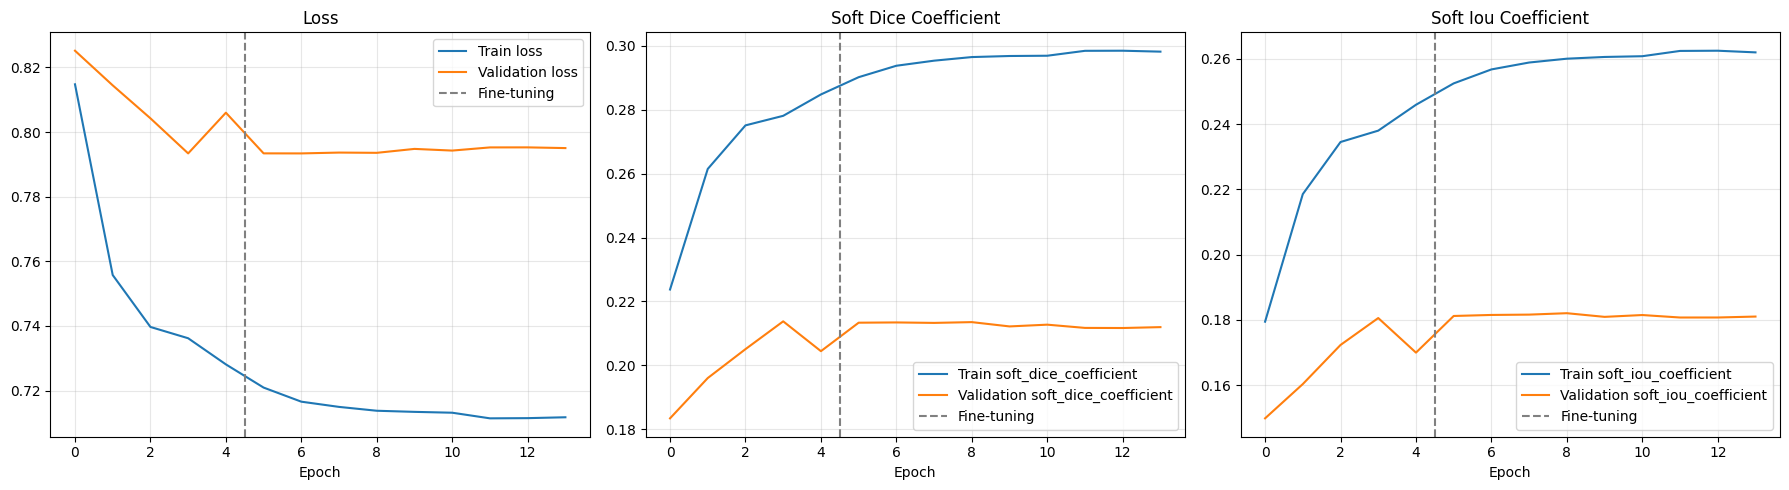

In [17]:
def merge_histories(*histories):
    merged = {}
    for history_item in histories:
        for metric_name, values in history_item.history.items():
            merged.setdefault(metric_name, []).extend(values)
    return merged

history = merge_histories(history_warmup, history_finetune)
metrics_to_plot = ["loss", "soft_dice_coefficient", "soft_iou_coefficient"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for axis, metric_name in zip(axes, metrics_to_plot):
    axis.plot(history[metric_name], label=f"Train {metric_name}")
    axis.plot(history[f"val_{metric_name}"], label=f"Validation {metric_name}")
    axis.axvline(
        completed_warmup_epochs - 0.5,
        color="gray",
        linestyle="--",
        label="Fine-tuning"
    )
    axis.set_title(metric_name.replace("_", " ").title())
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.3)
    axis.legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Validation threshold selection and comparable metrics

The original threshold grid and selection rule use validation predictions only. Soft and thresholded metrics use the same unrounded predictions from the selected saved model. Empty-mask rules, undefined subsets, and aggregation are implemented and checked in Python below.


In [18]:
# All validation/test metrics use the same masks and float32 probabilities.
# Soft scores are per-image averages unless explicitly named "global".
METRIC_DEFINITIONS = {
    "evaluation_unit": "MRI slice; train/validation/test remain patient-disjoint",
    "probability_precision": "float32 storage; float64 NumPy reductions",
    "threshold_rule": "foreground if probability > threshold (strict comparison)",
    "soft_smooth": 1e-6,
    "soft_dice": "mean over all images of (2*sum(y*p)+smooth)/(sum(y)+sum(p)+smooth)",
    "soft_global_dice": "same soft formula after summing over every image and pixel",
    "soft_iou": "mean over all images of (sum(y*p)+smooth)/(sum(y)+sum(p)-sum(y*p)+smooth)",
    "global_dice": "2*TP/(2*TP+FP+FN), pooled over all images and pixels",
    "global_iou": "TP/(TP+FP+FN), pooled over all images and pixels",
    "mean_dice_all": "unweighted mean of thresholded per-image Dice over all images",
    "mean_dice_positive": "same per-image Dice, restricted to nonempty ground-truth masks",
    "mean_iou_all": "unweighted mean of thresholded per-image IoU over all images",
    "positive_subset": "defined from ground truth only: sum(y_true) > 0",
    "thresholded_empty_policy": (
        "empty ground truth AND empty prediction: Dice=IoU=1; "
        "exactly one is empty: Dice=IoU=0; "
        "all-empty ground truth/prediction also gives global Dice=IoU=1"
    ),
    "soft_empty_policy": (
        "use the unchanged smooth formula, without thresholding: "
        "empty ground truth gives smooth/(sum(probabilities)+smooth); "
        "both exactly zero gives 1; small nonzero probabilities are penalized"
    ),
    "undefined_policy": (
        "missing positive/empty subsets and undefined precision/recall/specificity "
        "are None (JSON null, empty CSV cell), never an invented zero"
    ),
    "threshold_selection": (
        "validation only; original grid 0.10 to 0.90 step 0.10; "
        "maximize global_dice, then minimize empty_false_positive_rate"
    ),
}


def collect_predictions(dataset, model):
    true_batches = []
    probability_batches = []

    for images, masks in dataset:
        probabilities = np.asarray(model.predict_on_batch(images), dtype=np.float32)
        true_batch = np.asarray(masks.numpy())
        if probabilities.shape != true_batch.shape:
            raise ValueError("Prediction and ground-truth shapes differ.")
        if not np.all(np.isfinite(true_batch)) or not np.all((true_batch == 0) | (true_batch == 1)):
            raise ValueError("Ground-truth masks must contain only finite binary values.")
        if not np.all(np.isfinite(probabilities)):
            raise ValueError("Model probabilities contain NaN or infinity.")
        if np.any((probabilities < 0.0) | (probabilities > 1.0)):
            raise ValueError("Model probabilities must lie in [0, 1].")
        true_batches.append(true_batch.astype(np.uint8))
        # Do not quantize to float16 before thresholding or computing soft scores.
        probability_batches.append(probabilities)

    if not true_batches:
        raise ValueError("Cannot evaluate an empty dataset.")
    return np.concatenate(true_batches), np.concatenate(probability_batches)


def compute_segmentation_metrics(y_true, y_probability, threshold, smooth=1e-6):
    y_true = np.asarray(y_true)
    y_probability = np.asarray(y_probability)
    if y_true.shape != y_probability.shape:
        raise ValueError("Prediction and ground-truth shapes must match exactly.")
    if y_true.ndim != 4 or y_true.shape[-1] != 1 or y_true.size == 0:
        raise ValueError("Expected nonempty binary masks/probabilities of shape (N, H, W, 1).")
    if not np.all(np.isfinite(y_true)) or not np.all((y_true == 0) | (y_true == 1)):
        raise ValueError("Ground-truth masks must be finite and binary.")
    if not np.all(np.isfinite(y_probability)):
        raise ValueError("Probabilities contain NaN or infinity.")
    if np.any((y_probability < 0.0) | (y_probability > 1.0)):
        raise ValueError("Probabilities must lie in [0, 1].")
    if not np.isfinite(threshold) or not 0.0 <= threshold <= 1.0:
        raise ValueError("Threshold must be finite and in [0, 1].")
    if not np.isfinite(smooth) or smooth <= 0.0:
        raise ValueError("Soft-score smoothing must be finite and positive.")

    true_flat = y_true.reshape(len(y_true), -1).astype(bool)
    probability_flat = y_probability.reshape(len(y_probability), -1)
    pred_flat = probability_flat > threshold

    true_pixels = true_flat.sum(axis=1, dtype=np.float64)
    pred_pixels = pred_flat.sum(axis=1, dtype=np.float64)
    intersection = np.logical_and(true_flat, pred_flat).sum(axis=1, dtype=np.float64)
    dice_denominator = true_pixels + pred_pixels
    union = dice_denominator - intersection

    # Set 0/0 to 1 only for empty/empty thresholded masks.
    per_image_dice = np.divide(
        2.0 * intersection, dice_denominator,
        out=np.ones_like(intersection), where=dice_denominator > 0
    )
    per_image_iou = np.divide(
        intersection, union,
        out=np.ones_like(intersection), where=union > 0
    )

    # Preserve the training soft-score definition and its smoothing exactly.
    soft_intersection = (true_flat * probability_flat).sum(axis=1, dtype=np.float64)
    probability_sum = probability_flat.sum(axis=1, dtype=np.float64)
    soft_denominator = true_pixels + probability_sum
    per_image_soft_dice = (2.0 * soft_intersection + smooth) / (soft_denominator + smooth)
    per_image_soft_iou = (soft_intersection + smooth) / (
        soft_denominator - soft_intersection + smooth
    )

    positive_cases = true_pixels > 0
    empty_cases = ~positive_cases

    def subset_mean(values, selector):
        return float(values[selector].mean()) if np.any(selector) else None

    def defined_ratio(numerator, denominator):
        return float(numerator / denominator) if denominator > 0 else None

    tp = float(intersection.sum())
    fp = float(pred_pixels.sum() - tp)
    fn = float(true_pixels.sum() - tp)
    tn = float(true_flat.size - tp - fp - fn)
    global_dice_denominator = 2.0 * tp + fp + fn
    global_union = tp + fp + fn
    empty_false_positive_images = int(np.count_nonzero(pred_pixels[empty_cases] > 0))
    n_empty = int(empty_cases.sum())

    return {
        "threshold": float(threshold),
        "n_images": int(len(y_true)),
        "n_positive_images": int(positive_cases.sum()),
        "n_empty_images": n_empty,
        "soft_dice": float(per_image_soft_dice.mean()),
        "soft_dice_positive": subset_mean(per_image_soft_dice, positive_cases),
        "soft_dice_empty": subset_mean(per_image_soft_dice, empty_cases),
        "soft_global_dice": float(
            (2.0 * soft_intersection.sum() + smooth) / (soft_denominator.sum() + smooth)
        ),
        "soft_iou": float(per_image_soft_iou.mean()),
        "global_dice": float(2.0 * tp / global_dice_denominator) if global_dice_denominator > 0 else 1.0,
        "global_iou": float(tp / global_union) if global_union > 0 else 1.0,
        "mean_dice_all": float(per_image_dice.mean()),
        "mean_iou_all": float(per_image_iou.mean()),
        "mean_dice_positive": subset_mean(per_image_dice, positive_cases),
        "mean_iou_positive": subset_mean(per_image_iou, positive_cases),
        "mean_dice_empty": subset_mean(per_image_dice, empty_cases),
        "mean_iou_empty": subset_mean(per_image_iou, empty_cases),
        "precision": defined_ratio(tp, tp + fp),
        "recall_sensitivity": defined_ratio(tp, tp + fn),
        "specificity": defined_ratio(tn, tn + fp),
        "pixel_accuracy": float((tp + tn) / true_flat.size),
        "empty_false_positive_images": empty_false_positive_images,
        "empty_false_positive_rate": defined_ratio(empty_false_positive_images, n_empty),
        "tp_pixels": int(tp),
        "fp_pixels": int(fp),
        "fn_pixels": int(fn),
        "tn_pixels": int(tn),
    }


def check_soft_metric_agreement(y_true, y_probability, metrics, batch_size=BATCH_SIZE):
    """Verify NumPy evaluation against the actual TensorFlow training metric functions."""
    dice_metric = tf.keras.metrics.MeanMetricWrapper(soft_dice_per_image)
    iou_metric = tf.keras.metrics.MeanMetricWrapper(soft_iou_per_image)
    for start in range(0, len(y_true), batch_size):
        true_batch = tf.convert_to_tensor(y_true[start:start + batch_size], dtype=tf.float32)
        probability_batch = tf.convert_to_tensor(
            y_probability[start:start + batch_size], dtype=tf.float32
        )
        dice_metric.update_state(true_batch, probability_batch)
        iou_metric.update_state(true_batch, probability_batch)
    np.testing.assert_allclose(
        float(dice_metric.result().numpy()), metrics["soft_dice"],
        rtol=1e-5, atol=1e-6, equal_nan=False,
        err_msg="NumPy Soft Dice disagrees with the TensorFlow training metric."
    )
    np.testing.assert_allclose(
        float(iou_metric.result().numpy()), metrics["soft_iou"],
        rtol=1e-5, atol=1e-6, equal_nan=False,
        err_msg="NumPy Soft IoU disagrees with the TensorFlow training metric."
    )


In [19]:
def verify_evaluation_metrics():
    """Known-answer synthetic checks, independent of validation/test model results."""
    def masks(rows):
        return np.asarray(rows, dtype=np.float32).reshape(-1, 2, 2, 1)

    empty = masks([[0, 0, 0, 0]])
    positive = masks([[1, 0, 0, 0]])
    disjoint = masks([[0, 1, 0, 0]])
    perfect = compute_segmentation_metrics(positive, positive, 0.5)
    for key in ("soft_dice", "soft_iou", "global_dice", "global_iou", "mean_dice_all", "mean_dice_positive"):
        np.testing.assert_allclose(perfect[key], 1.0)
    assert perfect["empty_false_positive_rate"] is None

    both_empty = compute_segmentation_metrics(empty, empty, 0.5)
    for key in ("soft_dice", "soft_iou", "global_dice", "global_iou", "mean_dice_all", "mean_iou_all"):
        np.testing.assert_allclose(both_empty[key], 1.0)
    assert both_empty["mean_dice_positive"] is None
    assert both_empty["soft_dice_positive"] is None
    assert both_empty["precision"] is None
    assert both_empty["recall_sensitivity"] is None

    for true, probability in ((positive, empty), (empty, positive), (positive, disjoint)):
        metrics = compute_segmentation_metrics(true, probability, 0.5)
        for key in ("global_dice", "global_iou", "mean_dice_all", "mean_iou_all"):
            np.testing.assert_allclose(metrics[key], 0.0)

    # Soft Dice keeps small foreground probabilities; thresholded empty masks score 1.
    small_probability = compute_segmentation_metrics(empty, empty + 0.01, 0.5)
    np.testing.assert_allclose(small_probability["soft_dice"], 1e-6 / (0.04 + 1e-6), rtol=1e-6)
    assert small_probability["mean_dice_all"] == 1.0

    fractional = compute_segmentation_metrics(positive, masks([[0.75, 0.25, 0, 0]]), 0.5)
    np.testing.assert_allclose(fractional["soft_dice"], (1.5 + 1e-6) / (2.0 + 1e-6))
    np.testing.assert_allclose(fractional["soft_iou"], (0.75 + 1e-6) / (1.25 + 1e-6))
    assert fractional["global_dice"] == 1.0

    # Micro/global and macro/per-image scores differ correctly with lesion size.
    different_sizes = compute_segmentation_metrics(
        masks([[1, 1, 1, 1], [1, 0, 0, 0]]),
        masks([[1, 1, 1, 1], [0, 0, 0, 0]]), 0.5
    )
    np.testing.assert_allclose(different_sizes["global_dice"], 8.0 / 9.0)
    np.testing.assert_allclose(different_sizes["global_iou"], 4.0 / 5.0)
    np.testing.assert_allclose(different_sizes["mean_dice_all"], 0.5)

    mixed = compute_segmentation_metrics(
        masks([[1, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0]]),
        masks([[1, 0, 0, 0], [0, 0, 0, 0], [0, 1, 0, 0]]), 0.5
    )
    np.testing.assert_allclose(mixed["global_dice"], 2.0 / 3.0)
    np.testing.assert_allclose(mixed["mean_dice_all"], 2.0 / 3.0)
    np.testing.assert_allclose(mixed["mean_dice_positive"], 1.0)
    np.testing.assert_allclose(mixed["mean_dice_empty"], 0.5)
    np.testing.assert_allclose(mixed["empty_false_positive_rate"], 0.5)
    np.testing.assert_allclose(
        mixed["soft_dice"],
        (mixed["n_positive_images"] * mixed["soft_dice_positive"]
         + mixed["n_empty_images"] * mixed["soft_dice_empty"]) / mixed["n_images"]
    )

    # Preserve the original strict > rule, and probabilities just above the threshold.
    boundary = compute_segmentation_metrics(positive, masks([[0.50001, 0.5, 0, 0]]), 0.5)
    assert boundary["global_dice"] == 1.0

    check_soft_metric_agreement(
        masks([[1, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0]]),
        masks([[1, 0, 0, 0], [0, 0, 0, 0], [0, 1, 0, 0]]), mixed, batch_size=2
    )
    # Strict JSON serialization must accept missing subsets as null, not NaN.
    json.dumps([perfect, both_empty, mixed], allow_nan=False)

    for invalid_probability in (np.full_like(positive, np.nan), np.full_like(positive, 1.1)):
        try:
            compute_segmentation_metrics(positive, invalid_probability, 0.5)
        except ValueError:
            pass
        else:
            raise AssertionError("Invalid model probabilities were silently accepted.")
    print("Evaluation formula, empty-mask, threshold-boundary, and TensorFlow agreement checks passed.")


verify_evaluation_metrics()


Evaluation formula, empty-mask, threshold-boundary, and TensorFlow agreement checks passed.


In [20]:
val_true, val_probability = collect_predictions(val_ds, model)
thresholds = np.round(np.arange(0.10, 0.91, 0.10), 2)
threshold_df = pd.DataFrame([
    compute_segmentation_metrics(val_true, val_probability, threshold)
    for threshold in thresholds
])
threshold_df


,threshold,n_images,n_positive_images,n_empty_images,soft_dice,soft_dice_positive,soft_dice_empty,soft_global_dice,soft_iou,global_dice,...,precision,recall_sensitivity,specificity,pixel_accuracy,empty_false_positive_images,empty_false_positive_rate,tp_pixels,fp_pixels,fn_pixels,tn_pixels
0,0.1,386,109,277,0.213435,0.755834,5.899070e-07,0.798253,0.181546,0.782895,...,0.688121,0.907944,0.997921,0.997468,93,0.335740,115466,52333,11707,25117390
1,0.2,386,109,277,0.213435,0.755834,5.899070e-07,0.798253,0.181546,0.799595,...,0.726461,0.889104,0.998308,0.997759,77,0.277978,113070,42575,14103,25127148
2,0.3,386,109,277,0.213435,0.755834,5.899070e-07,0.798253,0.181546,0.807834,...,0.749946,0.875406,0.998525,0.997906,67,0.241877,111328,37120,15845,25132603
3,0.4,386,109,277,0.213435,0.755834,5.899070e-07,0.798253,0.181546,0.813500,...,0.769260,0.863139,0.998692,0.998010,54,0.194946,109768,32925,17405,25136798
4,0.5,386,109,277,0.213435,0.755834,5.899070e-07,0.798253,0.181546,0.816699,...,0.784951,0.851124,0.998822,0.998079,48,0.173285,108240,29654,18933,25140069
5,0.6,386,109,277,0.213435,0.755834,5.899070e-07,0.798253,0.181546,0.818909,...,0.800467,0.838220,0.998944,0.998136,40,0.144404,106599,26572,20574,25143151
6,0.7,386,109,277,0.213435,0.755834,5.899070e-07,0.798253,0.181546,0.819290,...,0.816173,0.822431,0.999064,0.998176,35,0.126354,104591,23557,22582,25146166
7,0.8,386,109,277,0.213435,0.755834,5.899070e-07,0.798253,0.181546,0.817919,...,0.834677,0.801821,0.999198,0.998205,32,0.115523,101970,20197,25203,25149526
8,0.9,386,109,277,0.213435,0.755834,5.899070e-07,0.798253,0.181546,0.811214,...,0.862244,0.765886,0.999382,0.998208,29,0.104693,97400,15561,29773,25154162


In [21]:
best_threshold_row = threshold_df.sort_values(
    ["global_dice", "empty_false_positive_rate"],
    ascending=[False, True]
).iloc[0]
best_threshold = float(best_threshold_row["threshold"])

# Reuse exactly the validation predictions used for threshold selection.
val_metrics = compute_segmentation_metrics(val_true, val_probability, best_threshold)
check_soft_metric_agreement(val_true, val_probability, val_metrics)
val_results_df = pd.DataFrame.from_dict(val_metrics, orient="index", columns=["value"])

print("Selected validation threshold:", best_threshold)
print("Validation metrics (all values from the selected model's validation predictions):")
display(val_results_df)


Selected validation threshold: 0.7
Validation metrics (all values from the selected model's validation predictions):


,value
threshold,7.000000e-01
n_images,3.860000e+02
n_positive_images,1.090000e+02
n_empty_images,2.770000e+02
soft_dice,2.134353e-01
soft_dice_positive,7.558336e-01
soft_dice_empty,5.899070e-07
soft_global_dice,7.982529e-01
soft_iou,1.815459e-01
global_dice,8.192902e-01


## 8. Final test evaluation

Evaluate test predictions once with the threshold already selected on validation. The validation and test tables use identical metric definitions. No test metric is used for threshold selection or model development.


In [22]:
# The validation-selected threshold is fixed before collecting test predictions.
test_true, test_probability = collect_predictions(test_ds, model)
test_metrics = compute_segmentation_metrics(test_true, test_probability, best_threshold)
check_soft_metric_agreement(test_true, test_probability, test_metrics)
test_results_df = pd.DataFrame.from_dict(test_metrics, orient="index", columns=["value"])

assert val_metrics["threshold"] == test_metrics["threshold"] == best_threshold
print("Test metrics (using the validation-selected threshold):")
display(test_results_df)


Test metrics (using the validation-selected threshold):


,value
threshold,7.000000e-01
n_images,3.780000e+02
n_positive_images,1.270000e+02
n_empty_images,2.510000e+02
soft_dice,2.582556e-01
soft_dice_positive,7.686655e-01
soft_dice_empty,4.557682e-07
soft_global_dice,8.268665e-01
soft_iou,2.236998e-01
global_dice,8.359426e-01


In [23]:
threshold_df.to_csv("validation_threshold_results.csv", index=False, na_rep="")
val_results_df.to_csv("validation_metrics.csv", index_label="metric", na_rep="")
test_results_df.to_csv("test_metrics.csv", index_label="metric", na_rep="")
split_df.to_csv("dataset_split_summary.csv", index=False)

for split_name, metrics in (("validation", val_metrics), ("test", test_metrics)):
    with open(f"{split_name}_metrics.json", "w", encoding="utf-8") as file:
        json.dump(
            {"split": split_name, "metrics": metrics, "metric_definitions": METRIC_DEFINITIONS},
            file, indent=2, allow_nan=False
        )

results_summary = {
    "seed": SEED,
    "image_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "selected_checkpoint_stage": selected_stage,
    "selected_threshold": best_threshold,
    "threshold_selected_on": "validation",
    "validation_metrics": val_metrics,
    "test_metrics": test_metrics,
    "validation_threshold_results": threshold_df.astype(object).where(
        pd.notna(threshold_df), None
    ).to_dict(orient="records"),
    "split_summary": split_df.to_dict(orient="records"),
    "metric_definitions": METRIC_DEFINITIONS,
    "training_metric_aggregation": "per-image MeanMetricWrapper; original loss and optimizer unchanged"
}

with open("results_summary.json", "w", encoding="utf-8") as file:
    json.dump(results_summary, file, indent=2, allow_nan=False)

print("Validation/test metric CSV and JSON files, threshold results, and split summary saved.")


Validation/test metric CSV and JSON files, threshold results, and split summary saved.


## 9. Prediction visualization

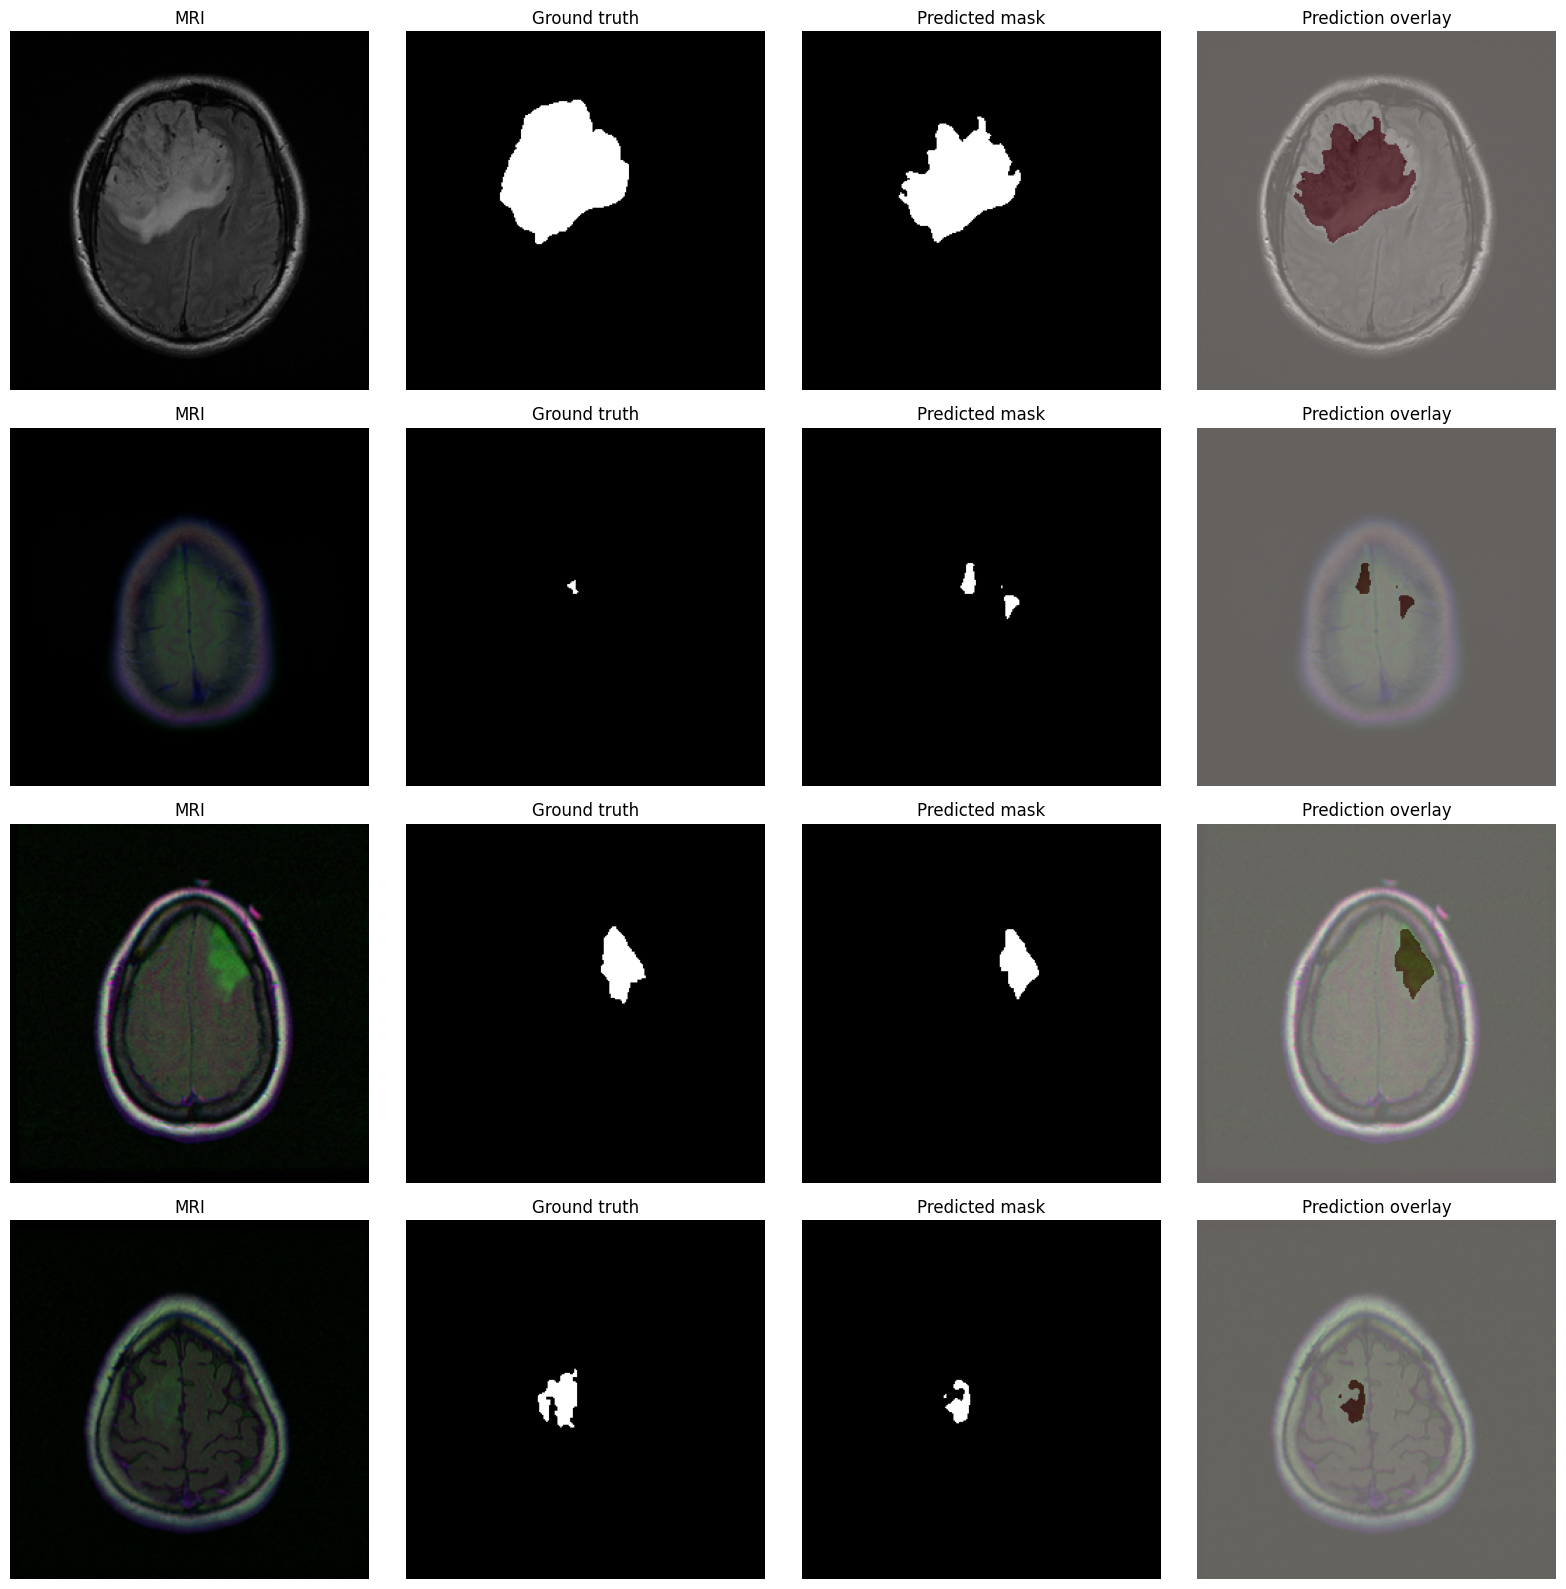

In [24]:
def denormalize_image(image):
    return np.clip((image + 1.0) / 2.0, 0.0, 1.0)

def visualize_positive_predictions(
    image_paths,
    mask_paths,
    model,
    threshold,
    num_samples=4,
    filename="prediction_results.png"
):
    positive_indices = [
        index for index, path in enumerate(mask_paths) if mask_is_positive(path)
    ]
    if not positive_indices:
        raise ValueError("No tumor-positive test slices were found.")

    sample_count = min(num_samples, len(positive_indices))
    selected_indices = np.random.default_rng(SEED).choice(
        positive_indices,
        size=sample_count,
        replace=False
    )

    fig, axes = plt.subplots(sample_count, 4, figsize=(16, 4 * sample_count))
    axes = np.atleast_2d(axes)

    for row, index in enumerate(selected_indices):
        image, mask = read_pair(image_paths[index], mask_paths[index])
        probability = model.predict(image[None, ...], verbose=0)[0, ..., 0]
        prediction = probability > threshold
        display_image = denormalize_image(image)

        axes[row, 0].imshow(display_image)
        axes[row, 0].set_title("MRI")
        axes[row, 1].imshow(mask[..., 0], cmap="gray")
        axes[row, 1].set_title("Ground truth")
        axes[row, 2].imshow(prediction, cmap="gray")
        axes[row, 2].set_title("Predicted mask")
        axes[row, 3].imshow(display_image)
        axes[row, 3].imshow(prediction, cmap="Reds", alpha=0.4)
        axes[row, 3].set_title("Prediction overlay")

        for axis in axes[row]:
            axis.axis("off")

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

visualize_positive_predictions(
    test_images,
    test_masks,
    model,
    threshold=best_threshold
)